In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print("Libraries loaded ✓")

Libraries loaded ✓


In [3]:
df = pd.read_csv('../data/property_listings.csv')
print(f"Shape: {df.shape}")
df.head(10)

Shape: (105, 8)


,Title,Price,Location,Address,Bedrooms,Bathrooms,Floor Size,Excerpt
0,4 Bedroom Apartment / Flat,KSh 27 000 000,Westlands,"Westlands, Westlands, Nairobi",4,4.0,211 m²,Duplex Apartments & Penthouses for Sale – West...
1,4 Bedroom Apartment / Flat,KSh 127 100 000,Westlands,"Donyo Sabuk Ave Nairobi, Westlands, Nairobi",4,5.5,514 m²,Your forest-front sanctuary awaits – sales now...
2,4 Bedroom Apartment / Flat,KSh 127 100 000,Westlands,"Donyo Sabuk Ave Nairobi, Westlands, Nairobi",4,5.5,514 m²,Your forest-front sanctuary awaits – sales now...
3,2 Bedroom Apartment / Flat,KSh 12 850 000,Westlands,"Westlands, Westlands, Nairobi",2,2.0,140 m²,"Discover the perfect combination of style, com..."
4,2 Bedroom Apartment / Flat,KSh 9 000 000,Kilimani,"Kilimani, Kilimani, Nairobi",2,2.0,88 m²,2 bedroom apartment for sale in Lavington\r\nL...
5,2 Bedroom Apartment / Flat,KSh 9 000 000,Kilimani,"Kilimani, Kilimani, Nairobi",2,2.0,88 m²,2 bedroom apartment for sale in Lavington\r\nL...
6,3 Bedroom Apartment / Flat,KSh 39 500 000,Westlands,"Donyo Sabuk Ave Nairobi, Westlands, Nairobi",3,4.5,230 m²,Your forest-front sanctuary awaits – sales now...
7,3 Bedroom Apartment / Flat,KSh 39 500 000,Westlands,"Donyo Sabuk Ave Nairobi, Westlands, Nairobi",3,4.5,230 m²,Your forest-front sanctuary awaits – sales now...
8,3 Bedroom Apartment / Flat,KSh 51 200 000,Westlands,"Donyo Sabuk Ave Nairobi, Westlands, Nairobi",3,4.5,287 m²,Your forest-front sanctuary awaits – sales now...
9,3 Bedroom Apartment / Flat,KSh 51 200 000,Westlands,"Donyo Sabuk Ave Nairobi, Westlands, Nairobi",3,4.5,287 m²,Your forest-front sanctuary awaits – sales now...


In [4]:
print(df.dtypes)
print("\nNull counts:")
print(df.isnull().sum())
print("\nN/A counts:")
for col in df.columns:
    print(f"{col}: {(df[col] == 'N/A').sum()}")

Title             str
Price             str
Location          str
Address           str
Bedrooms        int64
Bathrooms     float64
Floor Size        str
Excerpt           str
dtype: object

Null counts:
Title         0
Price         0
Location      0
Address       0
Bedrooms      0
Bathrooms     0
Floor Size    0
Excerpt       0
dtype: int64

N/A counts:
Title: 0
Price: 0
Location: 0
Address: 0
Bedrooms: 0
Bathrooms: 0
Floor Size: 0
Excerpt: 0


In [9]:
# Price format: "KSh 27 000 000" → remove KSh, remove spaces → float
df['price_clean'] = (
    df['Price']
    .str.replace('KSh', '', regex=False)
    .str.replace('\xa0', ' ', regex=False)  # handle non-breaking spaces
    .str.replace(' ', '', regex=False)       # remove all spaces (thousand separators)
    .str.strip()
)
df['price_clean'] = pd.to_numeric(df['price_clean'], errors='coerce')
print(df['price_clean'].describe())
print(f"\nFailed to parse: {df['price_clean'].isna().sum()}")

count    1.050000e+02
mean     1.910561e+07
std      1.977538e+07
min      4.680000e+06
25%      8.850000e+06
50%      1.200000e+07
75%      2.550000e+07
max      1.271000e+08
Name: price_clean, dtype: float64

Failed to parse: 0


In [6]:
df['floor_size_clean'] = (
    df['Floor Size']
    .str.replace('m²', '', regex=False)
    .str.replace('m2', '', regex=False)
    .str.strip()
)
df['floor_size_clean'] = pd.to_numeric(df['floor_size_clean'], errors='coerce')
print(df['floor_size_clean'].describe())

count    105.000000
mean     142.600000
std       99.531653
min       41.000000
25%       64.000000
50%      114.000000
75%      211.000000
max      514.000000
Name: floor_size_clean, dtype: float64


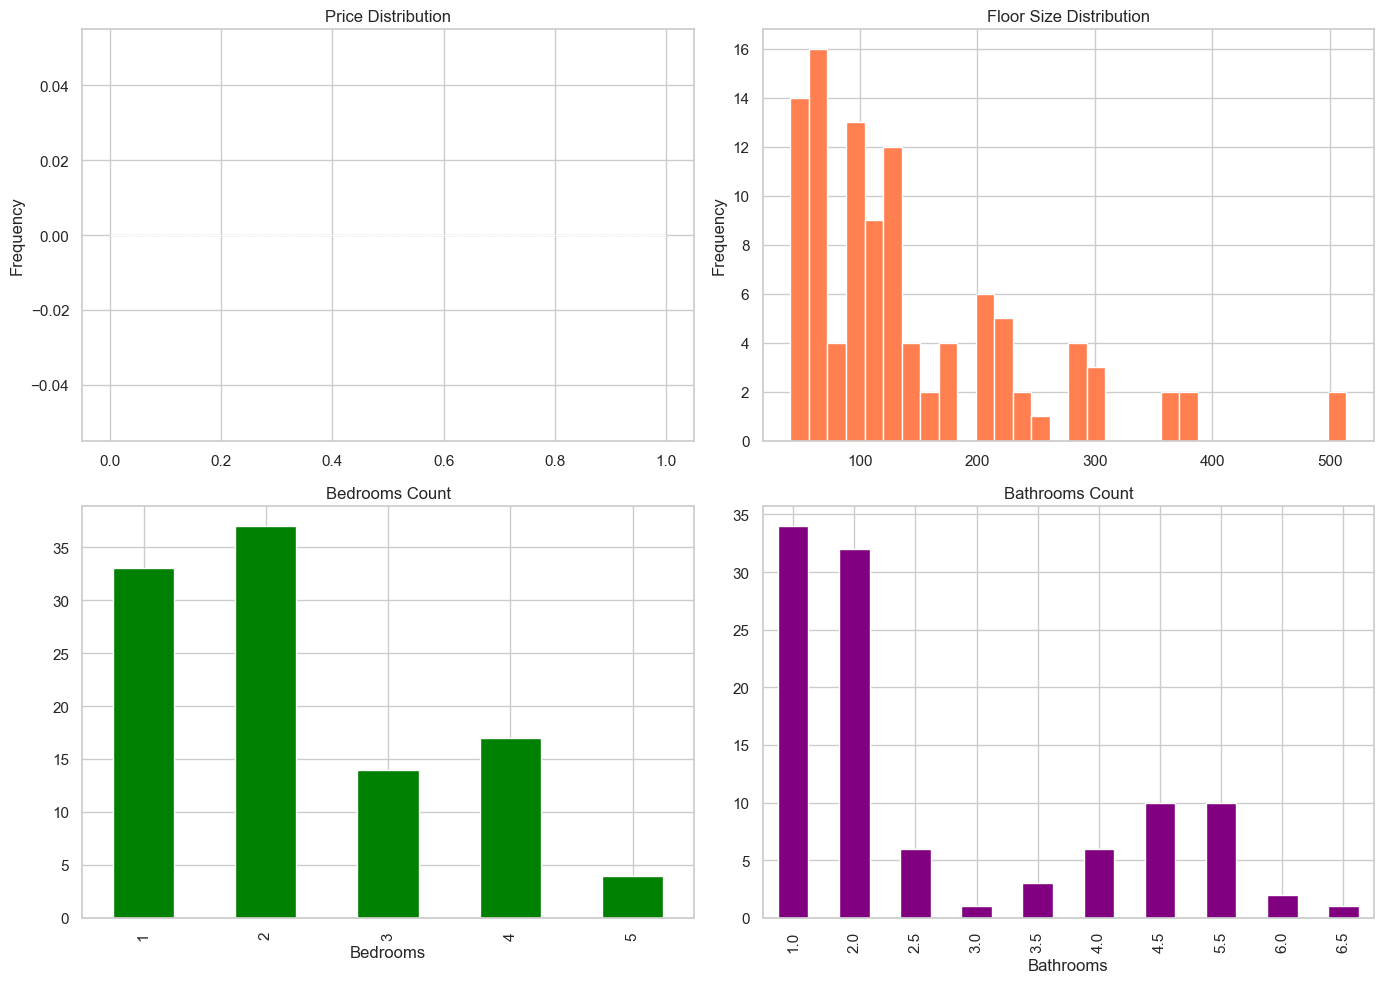

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df['price_clean'].dropna().plot(kind='hist', bins=30, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Price Distribution')

df['floor_size_clean'].dropna().plot(kind='hist', bins=30, ax=axes[0,1], color='coral')
axes[0,1].set_title('Floor Size Distribution')

df['Bedrooms'].value_counts().sort_index().plot(kind='bar', ax=axes[1,0], color='green')
axes[1,0].set_title('Bedrooms Count')

df['Bathrooms'].value_counts().sort_index().plot(kind='bar', ax=axes[1,1], color='purple')
axes[1,1].set_title('Bathrooms Count')

plt.tight_layout()
plt.savefig('../docs/eda_distributions.png')
plt.show()

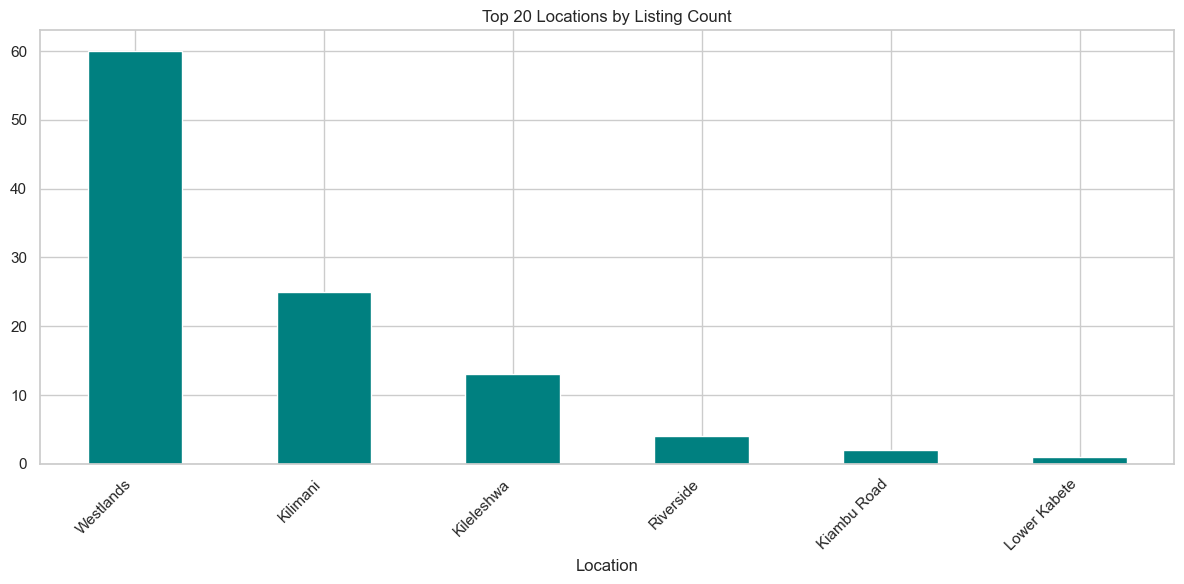

In [8]:
top_locations = df['Location'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_locations.plot(kind='bar', color='teal')
plt.title('Top 20 Locations by Listing Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../docs/eda_locations.png')
plt.show()

In [10]:
print(f"Before dedup: {df.shape[0]} rows")
df = df.drop_duplicates(subset=['Title', 'Price', 'Address', 'Floor Size'])
print(f"After dedup: {df.shape[0]} rows")

Before dedup: 105 rows
After dedup: 66 rows


In [11]:
df['price_per_sqm'] = df['price_clean'] / df['floor_size_clean']
print(df['price_per_sqm'].describe())

count        66.000000
mean     126211.324650
std       30883.334374
min       91785.714286
25%      105427.350427
50%      115097.822075
75%      139434.087644
max      250000.000000
Name: price_per_sqm, dtype: float64


In [14]:
import re

df['property_type'] = df['Title'].str.extract(r'(Apartment|House|Villa|Townhouse|Studio|Penthouse)', flags=re.IGNORECASE)
df['property_type'] = df['property_type'].fillna('Other').str.title()

df['bedrooms'] = pd.to_numeric(df['Bedrooms'], errors='coerce')
df['bathrooms'] = df['Bathrooms']

features = ['bedrooms', 'bathrooms', 'floor_size_clean', 'price_per_sqm', 'Location', 'property_type']
print(df[features + ['price_clean']].head(10))
print(f"\nProperty types found:\n{df['property_type'].value_counts()}")
print(f"\nLocations:\n{df['Location'].value_counts()}")

    bedrooms  bathrooms  floor_size_clean  price_per_sqm   Location  \
0          4        4.0               211  127962.085308  Westlands   
1          4        5.5               514  247276.264591  Westlands   
3          2        2.0               140   91785.714286  Westlands   
4          2        2.0                88  102272.727273   Kilimani   
6          3        4.5               230  171739.130435  Westlands   
8          3        4.5               287  178397.212544  Westlands   
10         4        5.5               379  173614.775726  Westlands   
13         3        2.0               140  141714.285714  Westlands   
14         1        1.0                67  120895.522388  Westlands   
15         1        1.0                58  163793.103448  Westlands   

   property_type  price_clean  
0      Apartment     27000000  
1      Apartment    127100000  
3      Apartment     12850000  
4      Apartment      9000000  
6      Apartment     39500000  
8      Apartment     51200

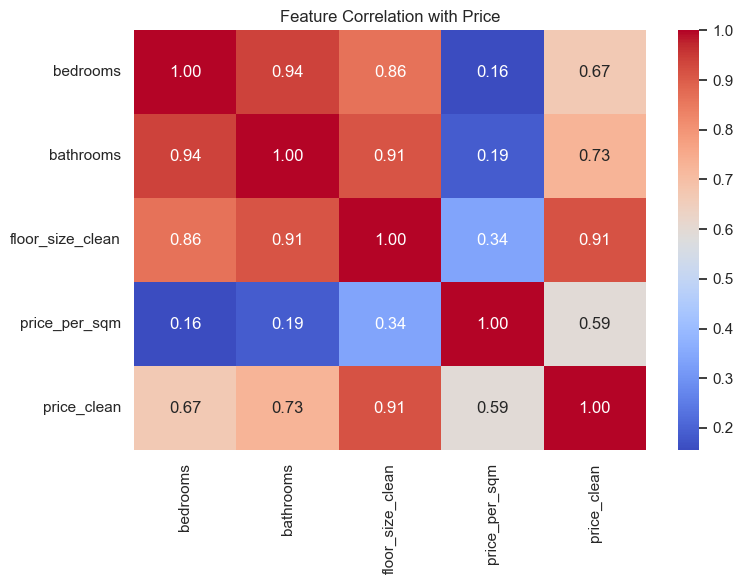

In [15]:
# Correlation heatmap
plt.figure(figsize=(8, 6))
corr_features = ['bedrooms', 'bathrooms', 'floor_size_clean', 'price_per_sqm', 'price_clean']
sns.heatmap(df[corr_features].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation with Price')
plt.tight_layout()
plt.savefig('../docs/eda_correlation.png')
plt.show()